In [1]:
# Importing Libraries
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, RocCurveDisplay)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42
DATA_PATH = Path("../data/heart.csv")   # run this notebook from the notebooks/ folder
FIG_DIR = Path("../docs/images")        # figures used in the README
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Loading Data Set
df = pd.read_csv(DATA_PATH)
print("Shape: ", df.shape)
df.head()

Shape:  (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
# Dataset Info:

print("DATA TYPES: ")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())
print("Unique rows:", df.drop_duplicates().shape[0])

#Dropping Duplicate Rows
df = df.drop_duplicates()
print("\nDuplicate rows:", df.duplicated().sum())

print("\nMISSING VALUES: ")
print(df.isnull().sum())

print("\nSTATISTICS: ")
df.describe()

DATA TYPES: 
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Duplicate rows: 723
Unique rows: 302

Duplicate rows: 0

MISSING VALUES: 
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

STATISTICS: 


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


### Label coding check (important)

In this Kaggle copy of the data, `target = 1` means **no** heart disease and `target = 0` means
**disease present**: the reverse of how the file is usually described. Evidence:

1. **Row-level match against the raw UCI Cleveland file** (`processed.cleveland.data`,
   [doi:10.24432/C52P4X](https://doi.org/10.24432/C52P4X)): all 302 de-duplicated rows here match a Cleveland
   patient on age, sex, resting BP and cholesterol, and in **302 of 302** of them `target == 1` coincides with the
   UCI diagnosis `num == 0` (no disease). Reproduce with `scripts/verify_label_coding.py`.
2. **Class counts:** UCI Cleveland has 164 patients with no disease and 139 with disease; here `target == 1` has 164 rows.
3. **Clinical direction:** before the fix, `exang`, `oldpeak` and `ca` (known risk markers) correlate *negatively* with the
   target and max heart rate `thalach` *positively*, which is the opposite of the expected direction for "disease".

The cell below flips the label so that **1 = disease present** everywhere else in this notebook. The CSV itself is not modified.

In [4]:
# Evidence visible from the data alone, BEFORE the fix (see the markdown above for the row-level UCI match)
raw_corr = df.corr()["target"]
print("raw target counts (1 / 0):", int((df['target'] == 1).sum()), "/", int((df['target'] == 0).sum()))
print("raw correlation with target -> exang: %+.3f, oldpeak: %+.3f, ca: %+.3f, thalach: %+.3f"
      % (raw_corr["exang"], raw_corr["oldpeak"], raw_corr["ca"], raw_corr["thalach"]))

df["target"] = 1 - df["target"]          # now: 1 = heart disease present, 0 = absent
print("after fix, target counts (1 = disease / 0 = no disease):",
      int((df['target'] == 1).sum()), "/", int((df['target'] == 0).sum()))

raw target counts (1 / 0): 164 / 138
raw correlation with target -> exang: -0.436, oldpeak: -0.429, ca: -0.409, thalach: +0.420
after fix, target counts (1 = disease / 0 = no disease): 138 / 164


In [5]:
# Data quirks: values outside the documented ranges of the UCI attribute description
# (ca should be 0-3, thal should be 1-3). They are kept, not "fixed", because the correct
# value is unknown; the counts are reported so the README can state this limitation.
print("Rows with ca == 4  :", int((df["ca"] == 4).sum()))
print("Rows with thal == 0:", int((df["thal"] == 0).sum()))
print("Value counts, ca  :", df["ca"].value_counts().sort_index().to_dict())
print("Value counts, thal:", df["thal"].value_counts().sort_index().to_dict())

Rows with ca == 4  : 4
Rows with thal == 0: 2
Value counts, ca  : {0: 175, 1: 65, 2: 38, 3: 20, 4: 4}
Value counts, thal: {0: 2, 1: 18, 2: 165, 3: 117}


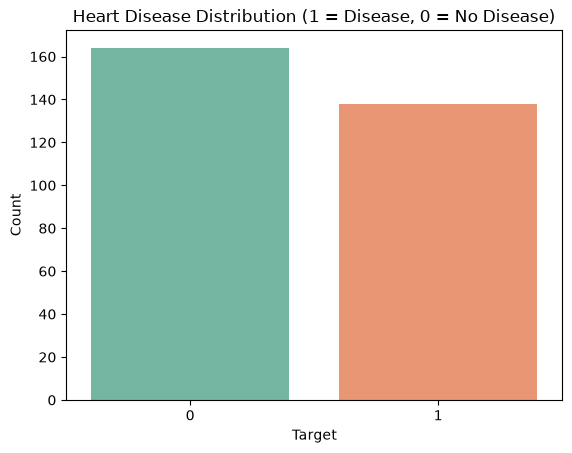


target
0    164
1    138
Name: count, dtype: int64


In [6]:
# TARGET VARIABLE DISTRIBUTION
# Where 1 means heart disease present, 0 means absent

sns.countplot(x = 'target', data = df, hue = 'target', palette = 'Set2', legend = False)
plt.title('Heart Disease Distribution (1 = Disease, 0 = No Disease)')
plt.xlabel('Target')
plt.ylabel('Count')
plt.savefig(FIG_DIR / '01_class_balance.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print(df['target'].value_counts())

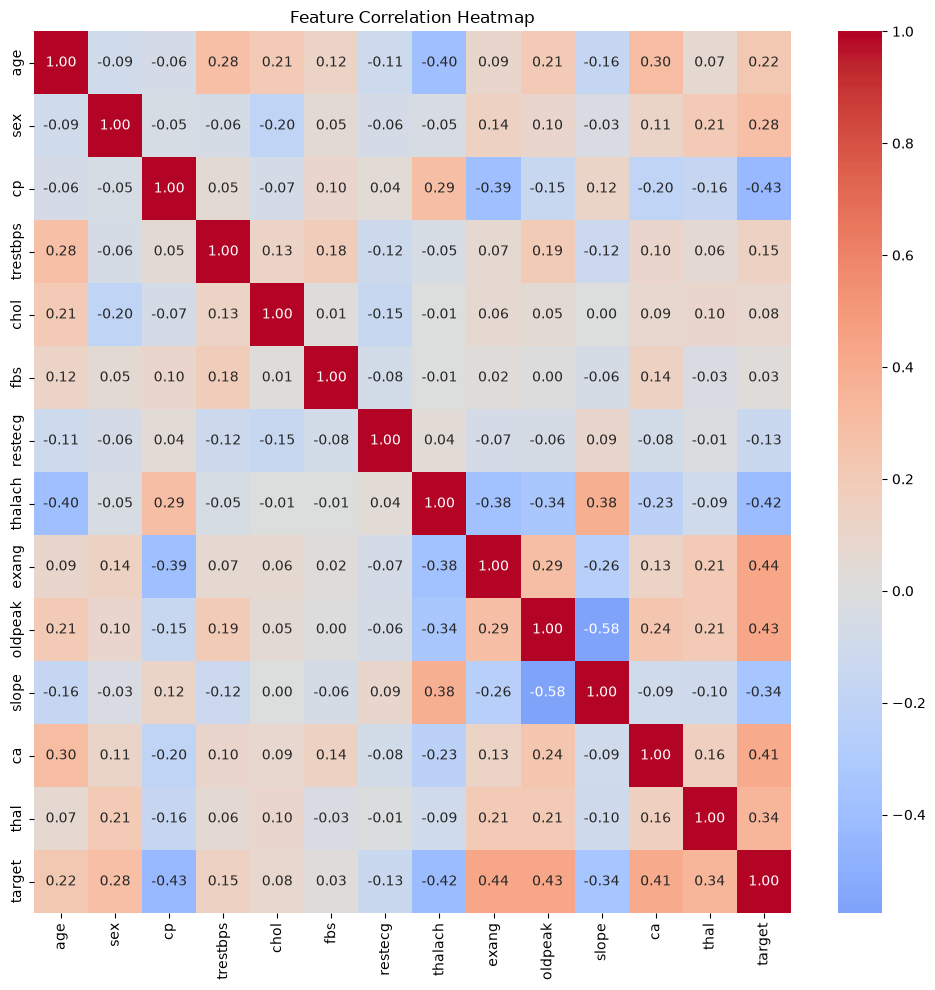

In [7]:
# COORELATION HEATMAP
# To see Which Features are related to eachother and target

plt.figure(figsize = (10, 10))
sns.heatmap(df.corr(), annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig(FIG_DIR / '02_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

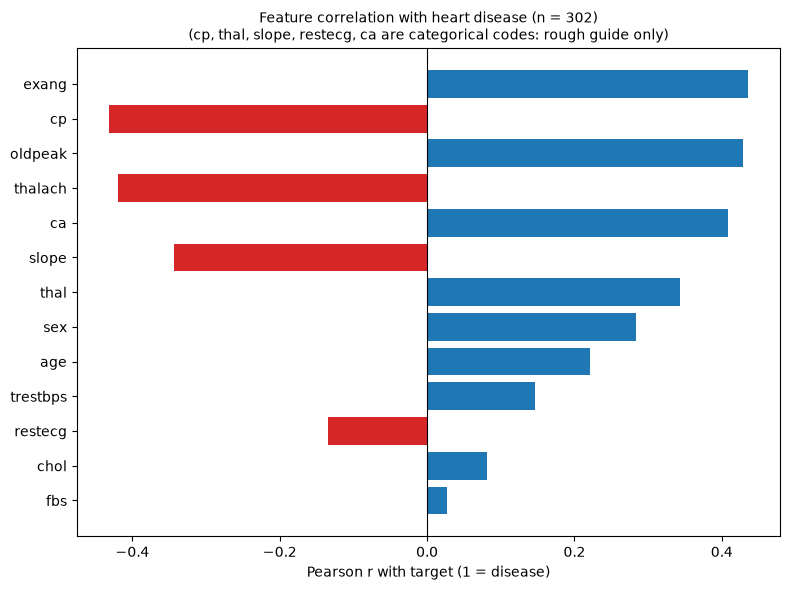

exang       0.436
cp         -0.432
oldpeak     0.429
thalach    -0.420
ca          0.409
slope      -0.344
thal        0.343
sex         0.284
age         0.221
trestbps    0.146
restecg    -0.135
chol        0.081
fbs         0.027


In [8]:
# Which features correlate most with the target? (Pearson r on the de-duplicated data)
corr = df.corr()["target"].drop("target").sort_values(key=abs, ascending=True)
plt.figure(figsize=(8, 6))
colors = ["tab:red" if v < 0 else "tab:blue" for v in corr.values]
plt.barh(corr.index, corr.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson r with target (1 = disease)")
plt.title("Feature correlation with heart disease (n = 302)\n(cp, thal, slope, restecg, ca are categorical codes: rough guide only)", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / '03_target_correlations.png', dpi=150, bbox_inches='tight')
plt.show()
print(corr.sort_values(key=abs, ascending=False).round(3).to_string())

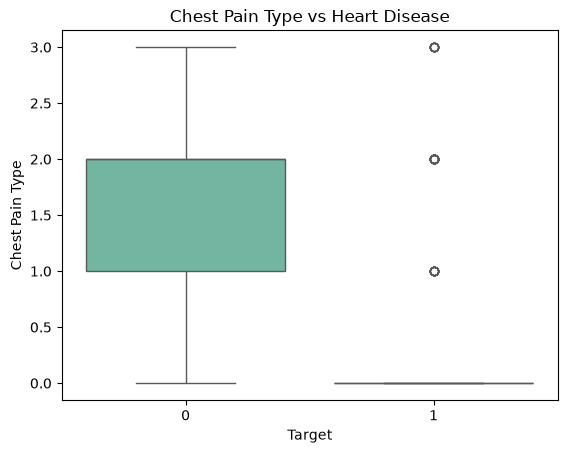

In [9]:
# CP VS HEARTDISEASE
sns.boxplot(x = 'target', y = 'cp', data = df, hue = 'target', palette = 'Set2', legend = False)
plt.title('Chest Pain Type vs Heart Disease')
plt.xlabel('Target')
plt.ylabel('Chest Pain Type')
plt.show()

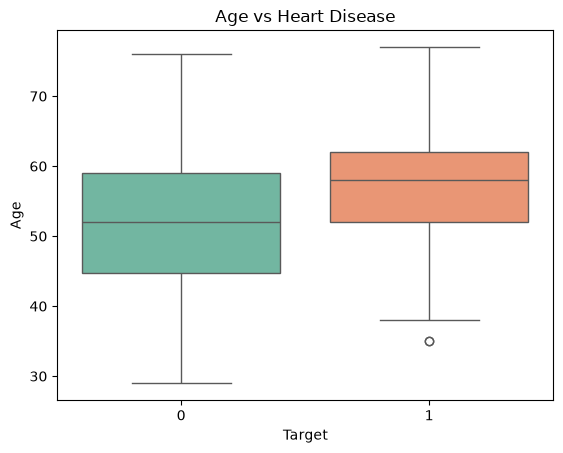

In [10]:
# AGE VS HEART DISEASE
sns.boxplot(x = 'target', y = 'age', data = df, hue = 'target', palette = 'Set2', legend = False)
plt.title('Age vs Heart Disease')
plt.xlabel('Target')
plt.ylabel('Age')
plt.show()

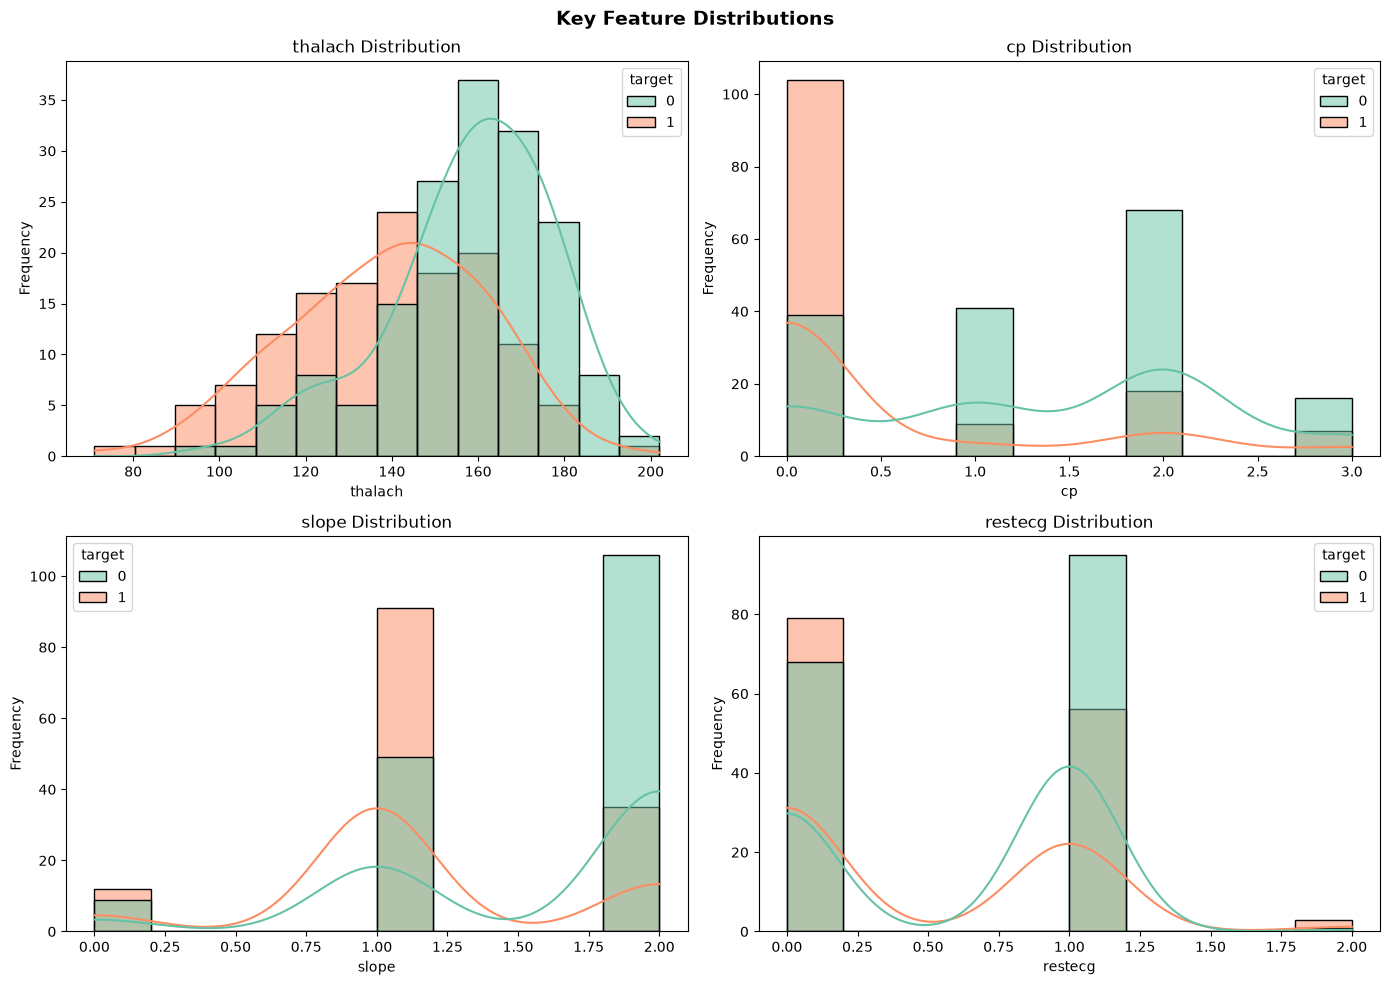

In [11]:
# KET FEATURE DISTRIBUTIONS
features = ['thalach', 'cp', 'slope', 'restecg']

fig, axes = plt.subplots(2, 2, figsize = (14, 10))

for i, feature in enumerate(features):
  ax = axes[i//2, i%2]
  sns.histplot(data = df, x = feature, hue = 'target', kde = True, ax= ax, palette = 'Set2')
  ax.set_xlabel(feature)
  ax.set_ylabel('Frequency')
  ax.set_title(f'{feature} Distribution')

plt.suptitle('Key Feature Distributions', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

In [12]:
# PREPROCESSING
# Understanding Our columns:

columns = {
    'age': 'Age',
    'sex': 'Sex',
    'cp': 'Chest Pain Type',
    'trestbps': 'Resting Blood Pressure',
    'chol': 'Cholesterol',
    'fbs': 'Fasting Blood Sugar',
    'restecg': 'Resting Electrocardiographic Results',
    'thalach': 'Maximum Heart Rate Achieved',
    'exang': 'Exercise Induced Angina',
    'oldpeak': 'ST Depression Induced by Exercise',
    'slope': 'Slope of the Peak Exercise ST Segment',
    'ca': 'Number of Major Vessels',
    'thal': 'Thalassemia',
    'target': 'Heart Disease'
}

for col, desc in columns.items():
  print(f"{col:10} -> {desc}")

age        -> Age
sex        -> Sex
cp         -> Chest Pain Type
trestbps   -> Resting Blood Pressure
chol       -> Cholesterol
fbs        -> Fasting Blood Sugar
restecg    -> Resting Electrocardiographic Results
thalach    -> Maximum Heart Rate Achieved
exang      -> Exercise Induced Angina
oldpeak    -> ST Depression Induced by Exercise
slope      -> Slope of the Peak Exercise ST Segment
ca         -> Number of Major Vessels
thal       -> Thalassemia
target     -> Heart Disease


In [13]:
#Splitting Columns and encoding data

categorical_cols = ['cp', 'restecg', 'slope', 'ca', 'thal']
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
binary_col = ['sex', 'fbs', 'exang']

df_encoded = pd.get_dummies(df, columns = categorical_cols, drop_first = True)

print("Shape before encoding: ", df.shape)
print("Shape after encoding: ", df_encoded.shape)
print("\nEncoded Data: ")
df_encoded.head()

Shape before encoding:  (302, 14)
Shape after encoding:  (302, 23)

Encoded Data: 


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,target,cp_1,...,restecg_2,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,52,1,125,212,0,168,0,1.0,1,False,...,False,False,True,False,True,False,False,False,False,True
1,53,1,140,203,1,155,1,3.1,1,False,...,False,False,False,False,False,False,False,False,False,True
2,70,1,145,174,0,125,1,2.6,1,False,...,False,False,False,False,False,False,False,False,False,True
3,61,1,148,203,0,161,0,0.0,1,False,...,False,False,True,True,False,False,False,False,False,True
4,62,0,138,294,1,106,0,1.9,1,False,...,False,True,False,False,False,True,False,False,True,False


In [14]:
# Separating Features and Target
X = df_encoded.drop('target', axis=1)
y = df_encoded['target']

print("Shape of Features: ", X.shape)
print("Shape of Target: ", y.shape)

Shape of Features:  (302, 22)
Shape of Target:  (302,)


In [15]:
# Train/Test split (stratified). Scaling is NOT applied here: it lives inside each model's
# Pipeline, so the scaler is fit only on the training portion of every CV fold (no leakage).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

preprocess = ColumnTransformer(
    [("scale", StandardScaler(), numerical_cols)],
    remainder="passthrough", verbose_feature_names_out=False)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")
print(f"Target balance in train: {y_train.value_counts().to_dict()}")
print(f"Target balance in test: {y_test.value_counts().to_dict()}")

Training set: 241 samples
Testing set: 61 samples
Target balance in train: {0: 131, 1: 110}
Target balance in test: {0: 33, 1: 28}


### Phase 4 - Model training

In [16]:
# Defining Models (every model is a Pipeline: scale numeric columns -> estimator)
models = {
    "Baseline (majority class)": Pipeline([("prep", clone(preprocess)),
        ("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression": Pipeline([("prep", clone(preprocess)),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("prep", clone(preprocess)),
        ("model", RandomForestClassifier(random_state=RANDOM_STATE))]),
    "XGBoost": Pipeline([("prep", clone(preprocess)),
        ("model", XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss"))]),
}
print("Models Defined: ")
for name in models:
    print(f" -> {name}")

Models Defined: 
 -> Baseline (majority class)
 -> Logistic Regression
 -> Random Forest
 -> XGBoost


In [17]:
# 5-fold stratified cross-validation on the TRAINING set only (AUC).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
print(f"{'Model':<28} {'Mean AUC':>10} {'Std AUC':>10}")
print("-" * 50)
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_results[name] = (scores.mean(), scores.std())
    print(f"{name:<28} {scores.mean():>10.4f} {scores.std():>10.4f}")

Model                          Mean AUC    Std AUC
--------------------------------------------------
Baseline (majority class)        0.5000     0.0000


Logistic Regression              0.9104     0.0359


Random Forest                    0.8896     0.0350


XGBoost                          0.8780     0.0252


In [18]:
# Training Models on the full training set
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"{name} trained!")

Baseline (majority class) trained!
Logistic Regression trained!
Random Forest trained!


XGBoost trained!


In [19]:
# Performance on the held-out test set (61 patients)
print(f"{'Model':<28} {'Acc':>7} {'Prec':>7} {'Recall':>7} {'F1':>7} {'AUC':>7}")
print("-" * 66)
test_results, test_proba, test_pred = {}, {}, {}
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    test_pred[name], test_proba[name] = y_pred, y_proba
    r = dict(Accuracy=accuracy_score(y_test, y_pred),
             Precision=precision_score(y_test, y_pred, zero_division=0),
             Recall=recall_score(y_test, y_pred),
             F1=f1_score(y_test, y_pred),
             AUC=roc_auc_score(y_test, y_proba))
    test_results[name] = r
    print(f"{name:<28} {r['Accuracy']:>7.4f} {r['Precision']:>7.4f} {r['Recall']:>7.4f} {r['F1']:>7.4f} {r['AUC']:>7.4f}")

Model                            Acc    Prec  Recall      F1     AUC
------------------------------------------------------------------
Baseline (majority class)     0.5410  0.0000  0.0000  0.0000  0.5000
Logistic Regression           0.8361  0.8462  0.7857  0.8148  0.9123
Random Forest                 0.8033  0.7667  0.8214  0.7931  0.8723
XGBoost                       0.8033  0.7667  0.8214  0.7931  0.8615


In [20]:
# How certain are these numbers? With only 61 test patients, differences of a few points
# are within noise. Bootstrap the TEST set (2,000 resamples) for 95% intervals.
rng = np.random.default_rng(RANDOM_STATE)
y_true = y_test.to_numpy()
n = len(y_true)
idx = rng.integers(0, n, size=(2000, n))

def boot(metric, name, proba=False):
    src_ = test_proba[name] if proba else test_pred[name]
    vals = []
    for ix in idx:
        if proba and len(np.unique(y_true[ix])) < 2:
            continue
        vals.append(metric(y_true[ix], src_[ix]))
    return np.percentile(vals, [2.5, 97.5])

print(f"{'Model':<28} {'Accuracy 95% CI':>20} {'AUC 95% CI':>20}")
print("-" * 70)
for name in trained_models:
    a = boot(accuracy_score, name)
    u = boot(roc_auc_score, name, proba=True)
    print(f"{name:<28} {f'[{a[0]:.3f}, {a[1]:.3f}]':>20} {f'[{u[0]:.3f}, {u[1]:.3f}]':>20}")

# Paired bootstrap: is Logistic Regression's accuracy lead over each other model distinguishable from zero?
print()
for other in ("Random Forest", "XGBoost"):
    diffs = [accuracy_score(y_true[ix], test_pred["Logistic Regression"][ix])
             - accuracy_score(y_true[ix], test_pred[other][ix]) for ix in idx]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    correct_lr = (test_pred["Logistic Regression"] == y_true)
    correct_o = (test_pred[other] == y_true)
    print(f"LogReg - {other:<14}: accuracy gap {np.mean(diffs):+.3f}, 95% CI [{lo:+.3f}, {hi:+.3f}]"
          f"  | patients LR got right but {other} missed: {int((correct_lr & ~correct_o).sum())},"
          f" the reverse: {int((~correct_lr & correct_o).sum())}")

Model                             Accuracy 95% CI           AUC 95% CI


----------------------------------------------------------------------


Baseline (majority class)          [0.426, 0.672]       [0.500, 0.500]


Logistic Regression                [0.738, 0.918]       [0.828, 0.974]


Random Forest                      [0.705, 0.902]       [0.777, 0.952]


XGBoost                            [0.705, 0.902]       [0.763, 0.946]



LogReg - Random Forest : accuracy gap +0.032, 95% CI [-0.049, +0.131]  | patients LR got right but Random Forest missed: 5, the reverse: 3


LogReg - XGBoost       : accuracy gap +0.032, 95% CI [-0.049, +0.115]  | patients LR got right but XGBoost missed: 4, the reverse: 2


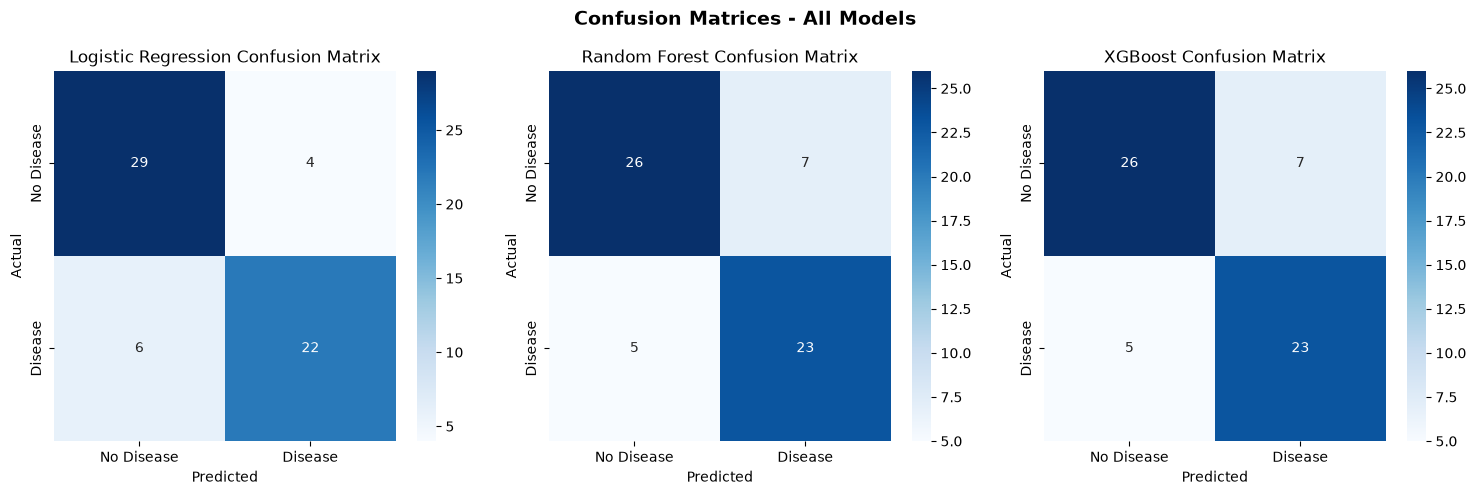

Logistic Regression    TN=29 FP= 4 FN= 6 TP=22 | sensitivity (recall)=0.786 specificity=0.879
Random Forest          TN=26 FP= 7 FN= 5 TP=23 | sensitivity (recall)=0.821 specificity=0.788
XGBoost                TN=26 FP= 7 FN= 5 TP=23 | sensitivity (recall)=0.821 specificity=0.788


In [21]:
# Confusion Matrices

fig, axes = plt.subplots(1, 3, figsize = (15, 5))

shown = {k: v for k, v in trained_models.items() if k != 'Baseline (majority class)'}
for ax, (name, model) in zip(axes, shown.items()):
  y_pred = model.predict(X_test)
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(cm, annot= True, fmt = 'd', cmap = 'Blues', ax = ax, xticklabels = ['No Disease', 'Disease'], yticklabels = ['No Disease', 'Disease'])
  ax.set_title(f'{name} Confusion Matrix')
  ax.set_xlabel('Predicted')
  ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices - All Models', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.savefig(FIG_DIR / '05_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()


# Interpretation: in a screening setting a FALSE NEGATIVE (a sick patient predicted healthy)
# is the costly error, so look at the counts, not just accuracy.
for name in shown:
    tn, fp, fn, tp = confusion_matrix(y_test, test_pred[name]).ravel()
    print(f"{name:<22} TN={tn:>2} FP={fp:>2} FN={fn:>2} TP={tp:>2} | "
          f"sensitivity (recall)={tp/(tp+fn):.3f} specificity={tn/(tn+fp):.3f}")

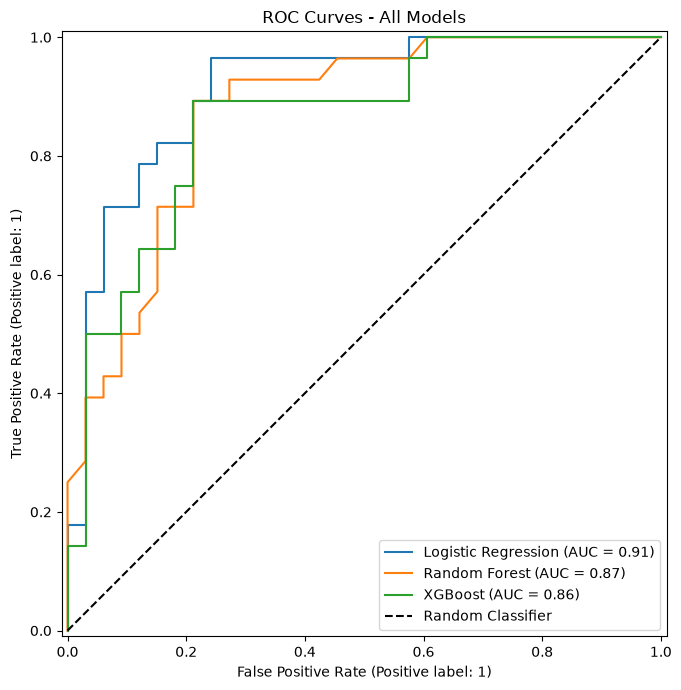

In [22]:
# ROC curves for all 3

fig, ax = plt.subplots(figsize = (10, 7))

for name, model in trained_models.items():
  if name.startswith('Baseline'):
    continue
  RocCurveDisplay.from_estimator(model, X_test, y_test, name = name, ax = ax)

ax.plot([0,1], [0,1], 'k--', label = 'Random Classifier')
ax.set_title('ROC Curves - All Models')
ax.legend(loc = 'lower right')
plt.tight_layout()
plt.savefig(FIG_DIR / '04_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [23]:
# Decision threshold: the default 0.5 is not sacred. Lowering it trades false alarms for
# fewer missed patients. Shown for Logistic Regression on the test set (61 patients).
p = test_proba["Logistic Regression"]
print(f"{'Threshold':>9} {'Sensitivity':>12} {'Specificity':>12} {'Precision':>10} {'FN':>4} {'FP':>4}")
for t in (0.3, 0.4, 0.5, 0.6, 0.7):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{t:>9.1f} {tp/(tp+fn):>12.3f} {tn/(tn+fp):>12.3f} {tp/max(tp+fp,1):>10.3f} {fn:>4} {fp:>4}")

Threshold  Sensitivity  Specificity  Precision   FN   FP
      0.3        0.929        0.758      0.765    2    8
      0.4        0.821        0.818      0.793    5    6
      0.5        0.786        0.879      0.846    6    4
      0.6        0.714        0.909      0.870    8    3
      0.7        0.679        0.939      0.905    9    2


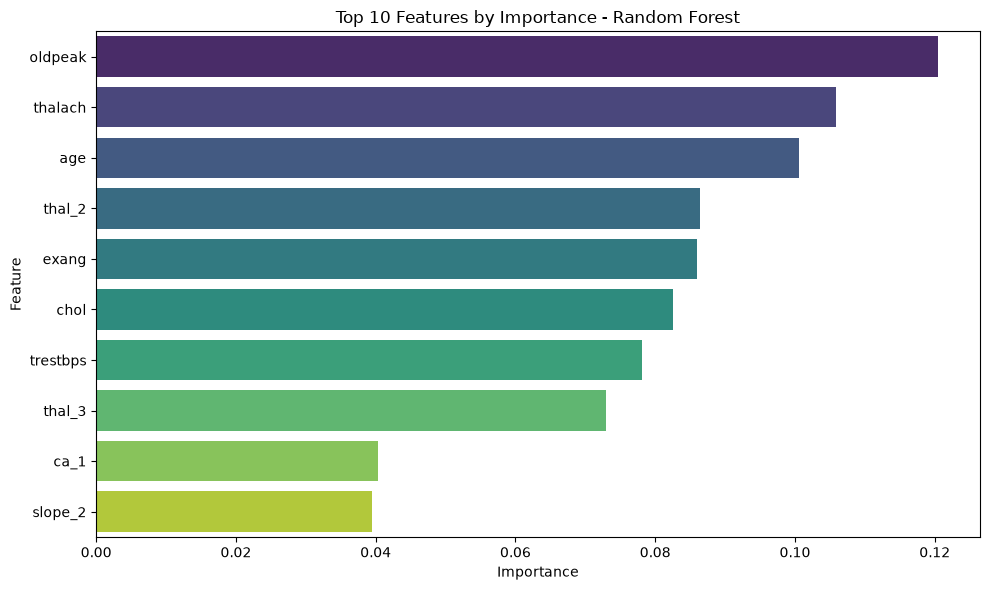

 Feature  Importance
 oldpeak      0.1205
 thalach      0.1059
     age      0.1005
  thal_2      0.0864
   exang      0.0860
    chol      0.0825
trestbps      0.0781
  thal_3      0.0730
    ca_1      0.0403
 slope_2      0.0394

Logistic Regression: largest |coefficient| (numeric features are standardised):
ca_2      1.994
ca_1      1.731
cp_3     -1.585
cp_2     -1.285
ca_3      1.112
sex       1.031
exang     0.782
thal_3    0.719


In [24]:
# Feature importance: Random Forest (impurity-based) and Logistic Regression (standardised coefficients)
rf = trained_models["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
feat_df = (pd.DataFrame({"Feature": names, "Importance": rf.named_steps["model"].feature_importances_})
           .sort_values("Importance", ascending=False).head(10))

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=feat_df, palette="viridis", legend=False, hue="Feature")
plt.title("Top 10 Features by Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(FIG_DIR / '06_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print(feat_df.round(4).to_string(index=False))

lr = trained_models["Logistic Regression"]
coef = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
print("\nLogistic Regression: largest |coefficient| (numeric features are standardised):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(8).round(3).to_string())

## Summary (every number below is printed by the cells above)

**Data.** 1,025 rows -> 723 exact duplicates removed -> **302 unique patients** (UCI Cleveland subset, via a Kaggle copy).
The label was re-coded so that `target = 1` means *disease present* (the Kaggle copy has it reversed; verified against the raw UCI file).

**Cross-validation** (5-fold on the 241 training patients, ROC AUC, scaler fit inside each fold):
Logistic Regression 0.910 +/- 0.036 | Random Forest 0.890 +/- 0.035 | XGBoost 0.878 +/- 0.025 | majority-class baseline 0.500.

**Held-out test set** (61 patients):

| Model | Accuracy | Recall (sensitivity) | Precision | F1 | AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.836 | 0.786 | 0.846 | 0.815 | 0.912 |
| Random Forest | 0.803 | 0.821 | 0.767 | 0.793 | 0.872 |
| XGBoost | 0.803 | 0.821 | 0.767 | 0.793 | 0.862 |
| Majority-class baseline | 0.541 | 0.000 | 0.000 | 0.000 | 0.500 |

**How much to trust it.** Logistic Regression has the best point estimates, but its accuracy lead over Random Forest and over
XGBoost is +3.2 points (about 2 patients out of 61) with a 95% bootstrap interval that includes zero. On this data the three
models are **not statistically distinguishable**; all clearly beat the baseline.

**Clinical reading.** At the default 0.5 threshold, Logistic Regression misses 6 of the 28 patients who have disease
(sensitivity 0.786). Lowering the threshold to 0.3 cuts that to 2 missed patients, at the cost of 8 false alarms among the
33 healthy patients. A real screening tool would need to choose the threshold from the cost of each error type.

**Limitations.** One dataset, 302 patients, a single 61-patient test split, no external validation; 4 rows have `ca = 4` and
2 rows have `thal = 0` (outside the documented ranges) and were kept; `cp`, `thal`, `slope`, `restecg` and `ca` are categorical
codes, so Pearson correlations on them are only a rough guide; Random Forest impurity importances favour continuous features.
This is a learning project, not a diagnostic tool.